In [54]:
import pandas as pd
from matplotlib import pyplot as plt

# Data inlezen en bekijken

https://zenodo.org/records/3574531 

In the file, the columns correspond to:

    ID: identifier of the animal
    Time: day of the tumor measurement after implantation
    Observation: tumor measurement (in mm3)


In [55]:
data = pd.read_csv("LM2-4LUC.txt", sep="\t")
print(data)

     ID  Time  Observation
0     0  22.0   621.290000
1     0  24.0   768.350000
2     0  27.0  1132.300000
3     0  28.0  1239.755000
4     0  32.0  1387.200000
..   ..   ...          ...
578  65  25.0  1060.866744
579  65  27.0  1016.310568
580  65  29.0  1041.071779
581  65  32.0  1901.515650
582  65  34.0  2036.072448

[583 rows x 3 columns]


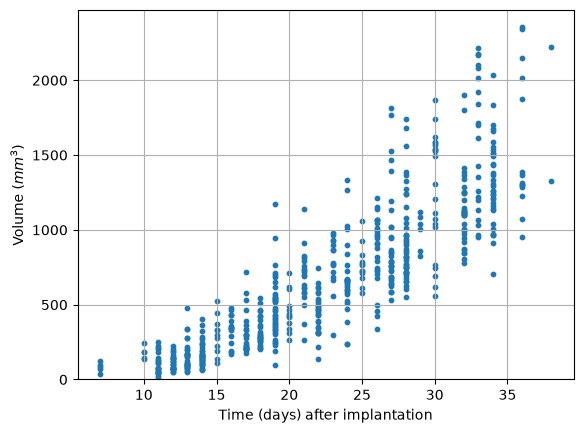

In [56]:
def plot_volume_time(data, marker_size = None, title = None):
    if marker_size:
        plt.scatter(x= data["Time"], y = data["Observation"], s = marker_size)
    else:
        plt.scatter(x= data["Time"], y = data["Observation"])
    plt.ylabel("Volume ($mm^3$)")
    plt.xlabel("Time (days) after implantation")
    plt.grid(visible = True)
    plt.ylim(bottom=0)
    if title:
        plt.title(title)

plot_volume_time(data, 10)
plt.show()

Dit zijn best veel datapunten en is hierdoor niet overzichtelijk. Ik denk het het eerst nuttiger is om de data per sample (ID) te bekijken. Ik ga filteren op de ID(s) met de meeste datapunten, en deze bekijken.

In [57]:
id_value_counts = data["ID"].value_counts()
# bekijk IDs met de meeste datapunten.
print(id_value_counts[0:10])

ID
33    15
34    15
35    15
36    15
37    15
38    15
51    11
55    11
56    11
57    11
Name: count, dtype: int64


In [58]:
top_value_count_ids = list(id_value_counts[id_value_counts == 15].index) # 15 is mixmaal aantal datapunten voor één ID
print(top_value_count_ids)

top_data = data[data["ID"].isin(top_value_count_ids)]

[33, 34, 35, 36, 37, 38]


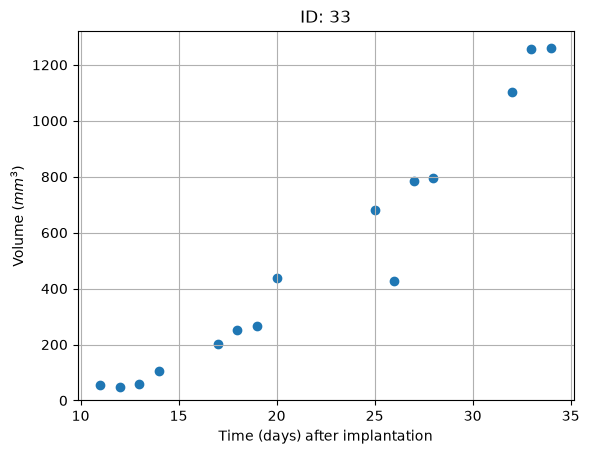

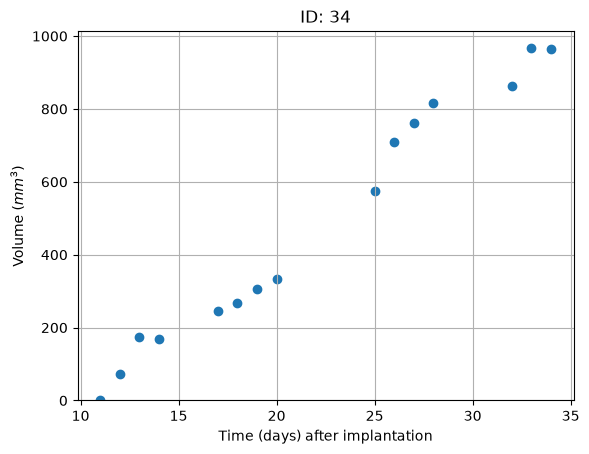

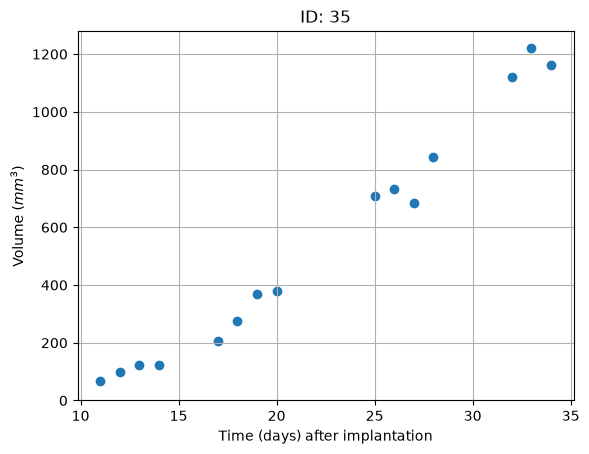

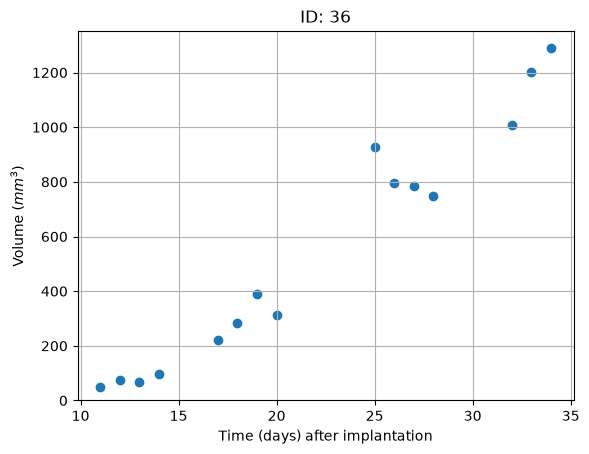

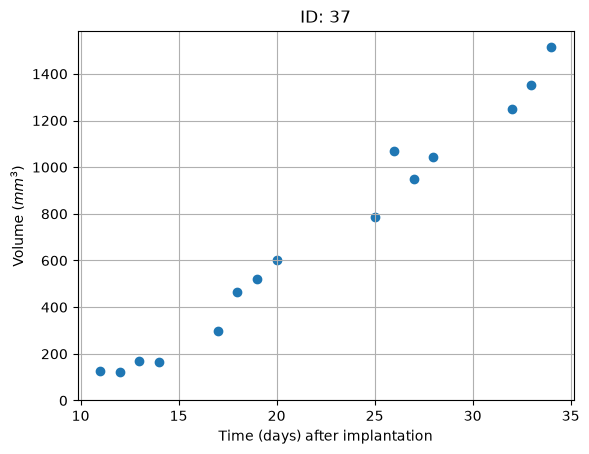

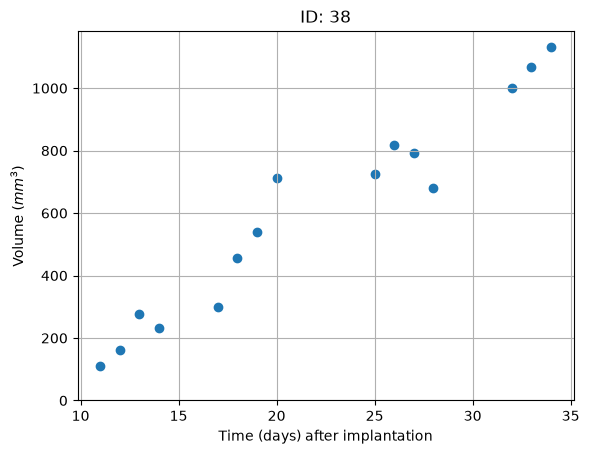

In [59]:
for id in top_value_count_ids:
    plot_volume_time(data[data["ID"] == id], title = f"ID: {id}")
    plt.show()

# Workshop 1 implementeren

Hiervoor heb ik de code van Brightspace van workshop 1 gekopieërd en aangepast zodat i.p.v. het SIR model het Bertalanffy model gebruikt, zoals beschreven uit het voorbeeld artikel [Treatment Optimization for Tumor Growth by Ordinary Differential Equations](https://www.researchgate.net/publication/378286328_Treatment_Optimization_for_Tumor_Growth_by_Ordinary_Differential_Equations).

In [ ]:
def bertalanffy_model(start_volume = 0.0001, alpha=0.25, beta=0.10, N=50, delta_t=1.0):
    """
    formule uit: https://www.researchgate.net/publication/378286328_Treatment_Optimization_for_Tumor_Growth_by_Ordinary_Differential_Equations
      alpha (float):    gemiddelde cel groei per dag
      beta (float):     gemiddelde cel dood per dag
      N (int):          aantal integratiestappen (aantal dagen)
      delta_t (float):  stapgrootte (in dagen)
    Retourneert:
      ts (list[float]): lijst met tijdstippen (dag)
      Vs (list[float]): lijst met volumes (mm^3)
    """
    t = 0.0
    ts = [t]
    volume = start_volume
    volumes = [start_volume]
    for _ in range(N):
        groei = (alpha * volume**(2/3)) - (beta * volume)
        t = t + delta_t
        volume = volume + groei
        ts.append(t)
        volumes.append(volume)
    return ts, volumes

def plot_bertalanffy(ts, volumes):
    """Plot de resultaten van het bertalanffy_model.
    Parameters:
      ts (list[float]): lijst met tijdstippen (dag)
      Ss (list[float]): lijst met volumes (mm^3)
    """
    plt.figure(figsize=(12.8, 4.8))
    plt.axvline(0.0, color='k')
    plt.plot(ts, volumes)
    plt.title('Bertalanffy model'); plt.xlabel("Time (days) after implantation"); plt.ylabel("Tumor volume ($mm^3$)"); 
    plt.ylim(bottom=0); plt.grid(True)

Ik heb voor nu voor de alpha en beta de zelfde waarden laten staan als in de voorbeeld code, omdat ik zelf geen goed beeld heb van wat hier goede waarden voor zouden kunnen zijn.

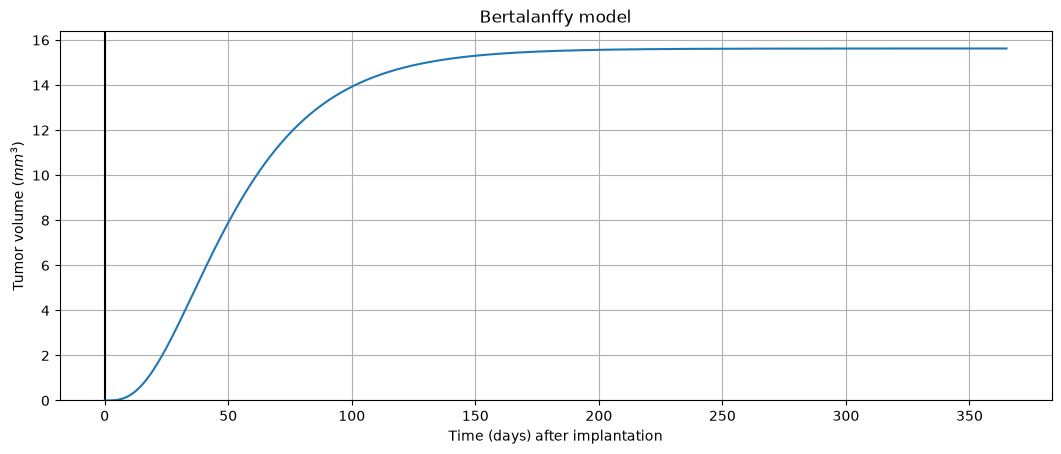

In [61]:
plot_bertalanffy(*bertalanffy_model())
plt.show()

Dit lijkt wel te werken. De volgende stap wat ik wil proberen is het (voor zo ver mogelijk) laten overeen komen met de echte data. 

Hiervoor zal ik de parameters van de `bertalanffy_model` functie handmatig wat aanpassen tot ik iets krijg wat er op lijkt. Ik overlap het ook met de echte data zodat het goed te vergelijken is. Voor het overlappen gebruik ik 1 van de willekeurig gekozen IDs uit de data die veel datapunten heeft die eerder bepaald zijn.

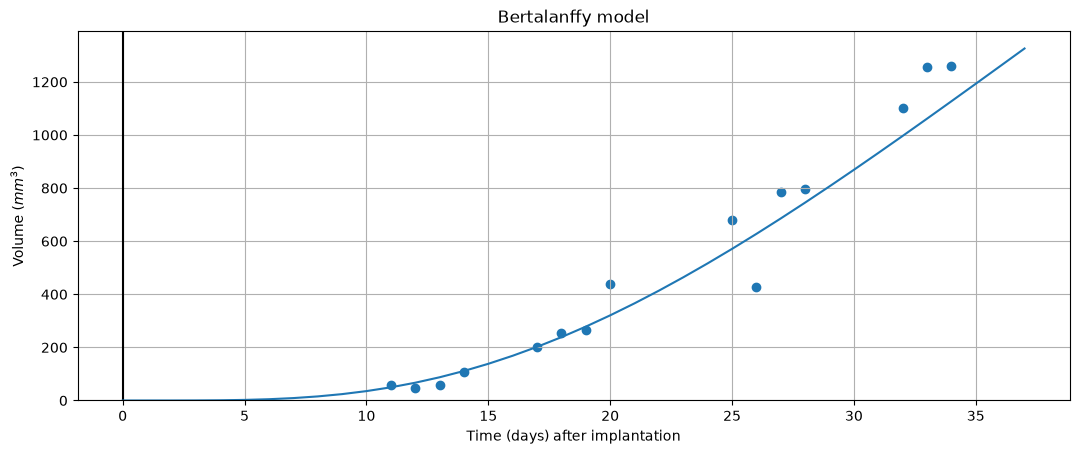

In [62]:
plot_bertalanffy(*bertalanffy_model(alpha=1.65, N=37))
plot_volume_time(data[data["ID"] == 33])
plt.show()

Dit lijkt opzich wel oke. Ik heb voor het bovenstaande alleen een hogere alpha (groeisnelheid) ingesteld. Ook is de hoveelheid dagen (default 50) veranderd naar 37 (dit is iets later dan laatst gemeten tijdstip voor ID 33). Dit laatste veranderd niet de uitkomst, maar zorgt dat de lijn eerder stopt waardoor het er iets beter uitziet.

Ik wil kijken of iets vergelijkbaars lukt met een andere beta waarde.

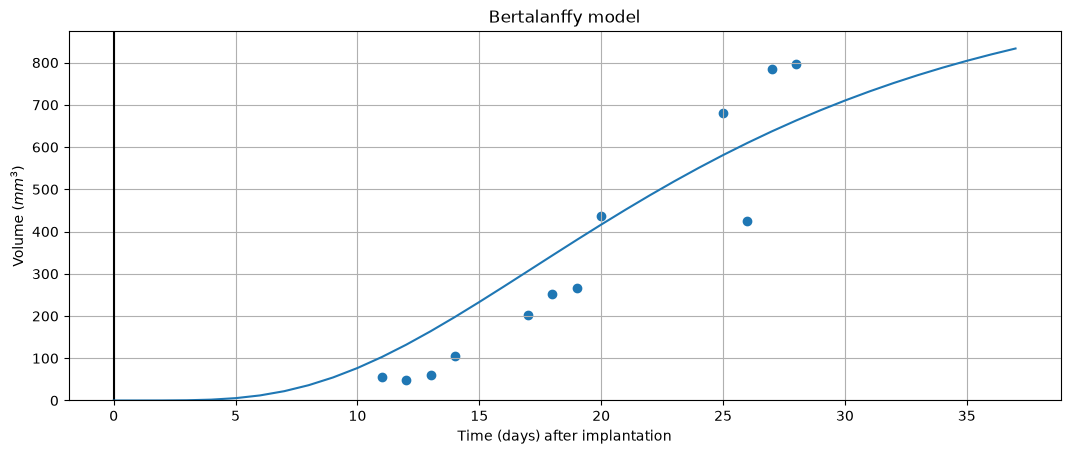

In [79]:
plot_bertalanffy(*bertalanffy_model(alpha = 2.5, beta=.25, N=37))
plot_volume_time(data[data["ID"] == 33])
plt.show()

De beta aanpassen veranderd de vorm van de curve, waardoor de lijn minder goed door de punten heen gaat. Het vorige voorbeeld lijkt dus beter.

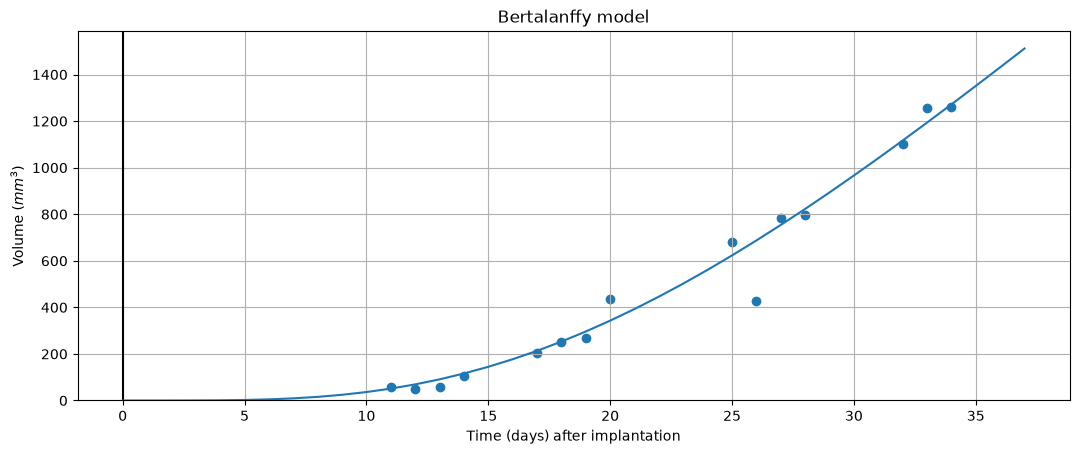

In [82]:
plot_bertalanffy(*bertalanffy_model(alpha = 1.65, beta=.09, N=37))
plot_volume_time(data[data["ID"] == 33])
plt.show()

Hier zou ik net zo lang mee door kunnen spelen, maar het lijkt het me de bedoeling om dit eigenlijk uiteindelijk te automatiseren, en dan ook voor verschillende modellen.